'diabetes_dataset_2000_synthetic.csv' not found. Please upload the file:


Saving diabetes_dataset_2000_synthetic.csv to diabetes_dataset_2000_synthetic.csv
Dataset Shape: (2000, 9)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            0      123             97              1        5  22.6   
1            0      138              3              0       19  43.0   
2           10      103             87             40       18  44.6   
3            1       97            129              2        0  22.2   
4            4      132             68             26      143  29.2   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.253   21        0  
1                     0.207   30        1  
2                     1.099   40        1  
3                     0.165   27        0  
4                     0.416   26        0  

MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression    0.7500   0.683761  0.559441  0.615385
1                  KNN    0.8500   

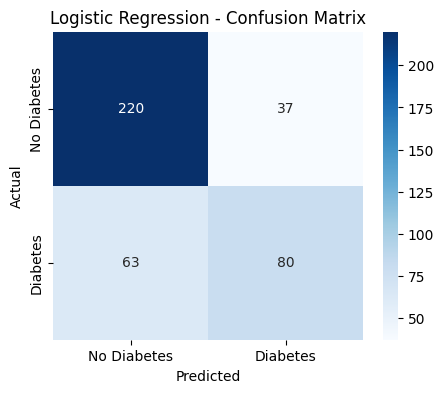

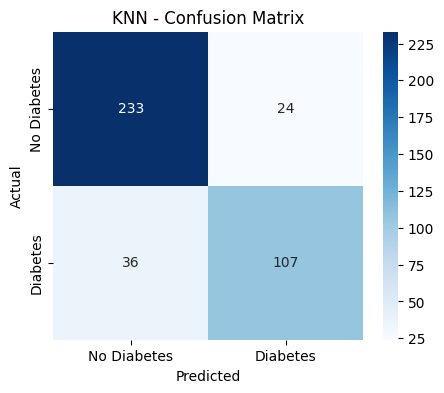

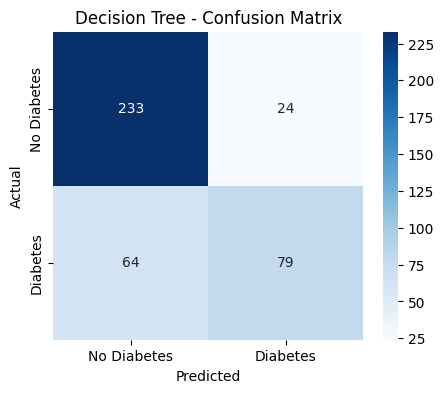

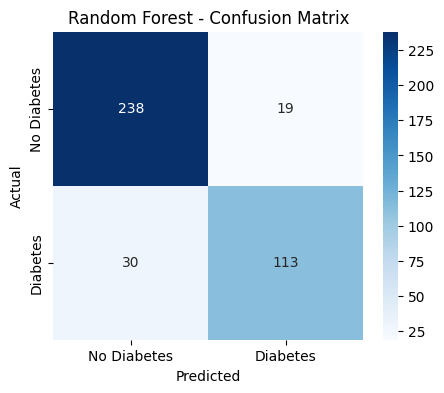

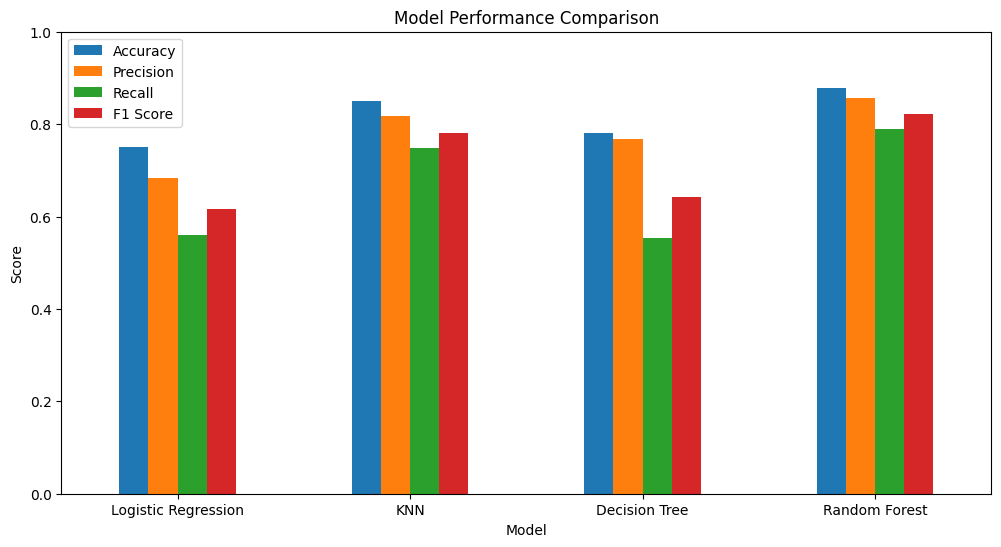


RANDOM FOREST FEATURE IMPORTANCE
                    Feature  Importance
1                   Glucose    0.260061
5                       BMI    0.159301
7                       Age    0.126763
6  DiabetesPedigreeFunction    0.125573
2             BloodPressure    0.087802
4                   Insulin    0.084290
3             SkinThickness    0.082957
0               Pregnancies    0.073255


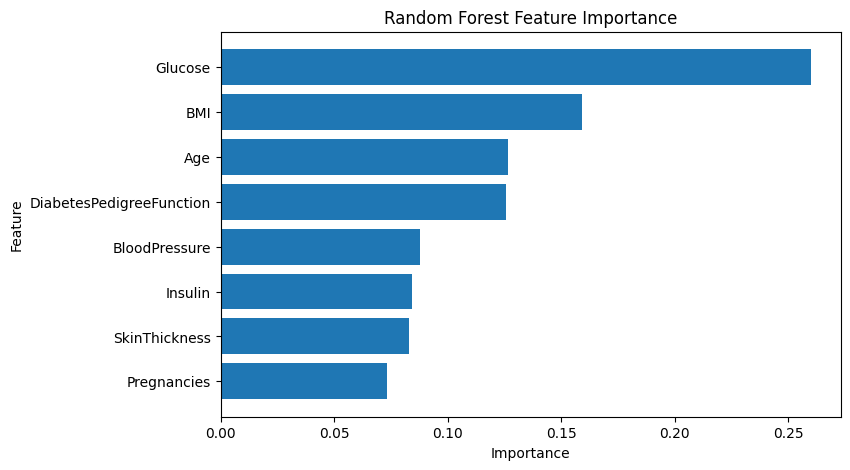


DIABETES PREDICTION
Diabetes Probability: 0.71
Prediction: Diabetes


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


In [ ]:
# ============================================================
# DIABETES PREDICTION - 4 ML ALGORITHMS COMPARISON
# Logistic Regression, KNN, Decision Tree, Random Forest
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# 1. LOAD DATASET
# ============================================================

dataset_name = "diabetes_dataset_2000_synthetic.csv"

# Check if file exists; if not, prompt user to upload
if not os.path.exists(dataset_name):
    print(f"'{dataset_name}' not found. Please upload the file:")
    uploaded = files.upload()

df = pd.read_csv(dataset_name)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


# ============================================================
# 2. HANDLE INVALID ZERO VALUES
# ============================================================

columns_to_replace = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[columns_to_replace] = df[columns_to_replace].replace(0, np.nan)


# ============================================================
# 3. SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop("Outcome", axis=1)
y = df["Outcome"]


# ============================================================
# 4. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# 5. HANDLE MISSING VALUES
# ============================================================

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 6. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)


# ============================================================
# 7. LOGISTIC REGRESSION
# ============================================================

model_lr = LogisticRegression(random_state=42)

model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)


# ============================================================
# 8. KNN
# ============================================================

model_knn = KNeighborsClassifier(
    n_neighbors=5
)

model_knn.fit(X_train_scaled, y_train)

y_pred_knn = model_knn.predict(X_test_scaled)


# ============================================================
# 9. DECISION TREE
# ============================================================

model_dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model_dt.fit(X_train_scaled, y_train)

y_pred_dt = model_dt.predict(X_test_scaled)


# ============================================================
# 10. RANDOM FOREST
# ============================================================

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train_scaled, y_train)

y_pred_rf = model_rf.predict(X_test_scaled)


# ============================================================
# 11. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})


print("\n================================")
print("MODEL COMPARISON")
print("================================")

print(comparison)


# ============================================================
# 12. FIND BEST MODEL
# ============================================================

best_model = comparison.loc[
    comparison["F1 Score"].idxmax()
]

print("\n================================")
print("BEST MODEL")
print("================================")

print("Model    :", best_model["Model"])
print("Accuracy :", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall   :", round(best_model["Recall"], 4))
print("F1 Score :", round(best_model["F1 Score"], 4))


# ============================================================
# 13. CONFUSION MATRICES
# ============================================================

models = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

for model_name, predictions in models.items():

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(model_name + " - Confusion Matrix")

    plt.show()


# ============================================================
# 14. PERFORMANCE COMPARISON GRAPH
# ============================================================

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()

plt.show()


# ============================================================
# 15. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model_rf.feature_importances_

}).sort_values(
    by="Importance",
    ascending=False
)

print("\n================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("================================")

print(importance)


plt.figure(figsize=(8, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()


# ============================================================
# 16. FINAL RANDOM FOREST PREDICTION FUNCTION
# ============================================================

def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
):

    patient = np.array([[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree,
        age
    ]])

    # Handle missing values
    patient_imputed = imputer.transform(patient)

    # Scale features
    patient_scaled = scaler.transform(patient_imputed)

    # Prediction
    prediction = model_rf.predict(patient_scaled)[0]

    # Probability
    probability = model_rf.predict_proba(patient_scaled)[0][1]

    print("\n================================")
    print("DIABETES PREDICTION")
    print("================================")

    print("Diabetes Probability:", round(probability, 3))

    if prediction == 1:
        print("Prediction: Diabetes")
    else:
        print("Prediction: No Diabetes")


# ============================================================
# 17. TEST NEW PATIENT
# ============================================================

predict_diabetes(
    pregnancies=2,
    glucose=140,
    blood_pressure=70,
    skin_thickness=30,
    insulin=100,
    bmi=32.0,
    diabetes_pedigree=0.5,
    age=40
)